<a href="https://colab.research.google.com/github/izidiohenrique10-design/Wine-quality-classification-Trabalho-Parcial---Ci-ncia-de-Dados-e-Intelig-ncia-Artificial/blob/main/qualidade_vinho.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Perguntas que serão investigadas

Durante a análise serão investigadas as seguintes hipóteses:

1. Vinhos considerados de boa qualidade possuem maior teor alcoólico?
2. A acidez volátil está relacionada à qualidade do vinho?
3. Quais características físico-químicas apresentam maior relação com a qualidade?
4. É possível prever se um vinho possui boa qualidade utilizando apenas suas características físico-químicas?
5. Qual dos modelos apresenta melhor desempenho: KNN ou Random Forest?

## 1. bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import joblib
import warnings
warnings.filterwarnings("ignore")

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


## 2. Carregamento do dataset

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Dataset carregado com sucesso!")
print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

df.head()

Dataset carregado com sucesso!
Quantidade de linhas: 1599
Quantidade de colunas: 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Conhecendo o conjunto de dados

In [ ]:
print("Dimensões do dataset:")
print(df.shape)

print("\nTipos das variáveis:")
print(df.dtypes)

print("\nInformações gerais:")
df.info()

Dimensões do dataset:
(1599, 12)

Tipos das variáveis:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total 

## 4. Estatísticas

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


## 5. Verificação de valores ausentes

In [ ]:
print("Quantidade de valores ausentes por coluna:")

missing = df.isnull().sum()

print(missing)

if missing.sum() == 0:
    print("\nNão existem valores ausentes no dataset.")
else:
    print("\nExistem valores ausentes.")

Quantidade de valores ausentes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Não existem valores ausentes no dataset.


## 6. Verificação de registros duplicados

In [ ]:
duplicados = df.duplicated().sum()

print(f"Quantidade de registros duplicados: {duplicados}")

Quantidade de registros duplicados: 240


## 7. Distribuição da qualidade dos vinhos

Antes de transformar a variável `quality` em uma variável binária, vamos observar como estão distribuídas as notas de qualidade.

### Pergunta

**Como as notas de qualidade estão distribuídas no conjunto de dados?**

Essa análise é importante porque permite verificar se algumas categorias possuem muito mais exemplos que outras.

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


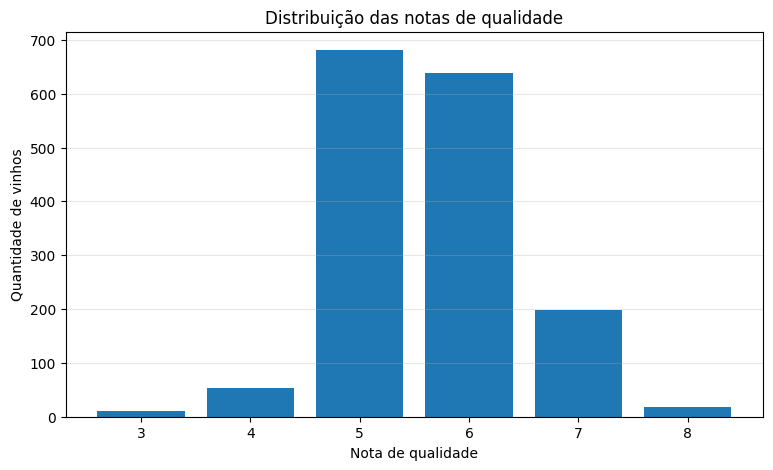

In [ ]:
quality_counts = df["quality"].value_counts().sort_index()

print(quality_counts)

plt.figure(figsize=(9, 5))

plt.bar(
    quality_counts.index.astype(str),
    quality_counts.values
)

plt.title("Distribuição das notas de qualidade")
plt.xlabel("Nota de qualidade")
plt.ylabel("Quantidade de vinhos")
plt.grid(axis="y", alpha=0.3)

plt.show()

## 8. Criação da variável alvo

A regra utilizada será:

- qualidade >= 6 → `1` = boa qualidade
- qualidade < 6 → `0` = baixa qualidade

In [ ]:
df["good_quality"] = np.where(df["quality"] >= 6, 1, 0)

print(df["good_quality"].value_counts())

print("\nPercentual de cada classe:")
print(df["good_quality"].value_counts(normalize=True) * 100)

good_quality
1    855
0    744
Name: count, dtype: int64

Percentual de cada classe:
good_quality
1    53.470919
0    46.529081
Name: proportion, dtype: float64


## 9. Distribuição da variável alvo

Agora vamos observar a quantidade de vinhos classificados como:

- baixa qualidade;
- boa qualidade.

Essa etapa permite verificar se existe um desbalanceamento entre as classes.

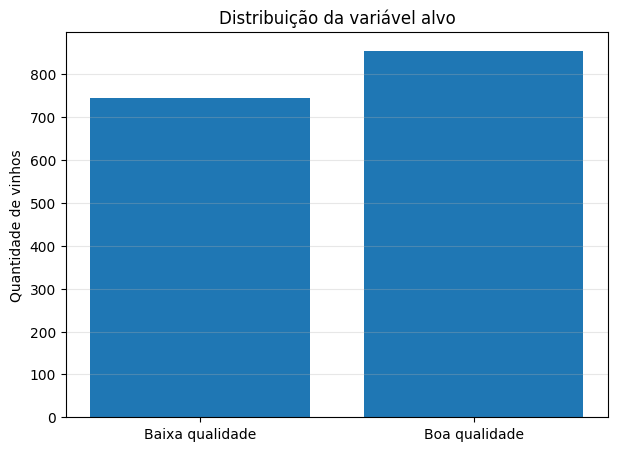

In [ ]:
target_counts = df["good_quality"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Baixa qualidade", "Boa qualidade"],
    target_counts.values
)

plt.title("Distribuição da variável alvo")
plt.ylabel("Quantidade de vinhos")
plt.grid(axis="y", alpha=0.3)

plt.show()

## 10. Hipótese 1 — Teor alcoólico

### Pergunta

**Vinhos classificados como de boa qualidade apresentam maior teor alcoólico, em média, do que vinhos de baixa qualidade?**

In [ ]:
alcool_media = df.groupby("good_quality")["alcohol"].mean()

print("Teor alcoólico médio:")

print(f"Baixa qualidade: {alcool_media[0]:.2f}%")
print(f"Boa qualidade: {alcool_media[1]:.2f}%")

Teor alcoólico médio:
Baixa qualidade: 9.93%
Boa qualidade: 10.86%


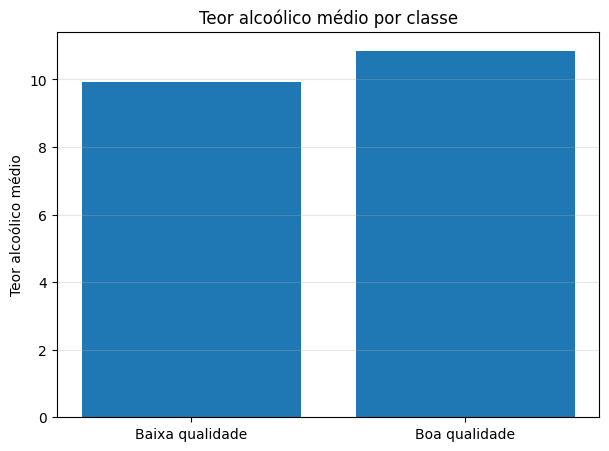

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Baixa qualidade", "Boa qualidade"],
    alcool_media.values
)

plt.title("Teor alcoólico médio por classe")
plt.ylabel("Teor alcoólico médio")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Resposta da Hipótese 1

Caso a média de álcool dos vinhos de boa qualidade seja maior, isso fornece evidência de que o teor alcoólico pode estar associado à classificação de qualidade.

Entretanto, uma diferença de médias não significa necessariamente que o álcool seja a causa da maior qualidade. Ela apenas indica uma associação nos dados analisados.

## 11. Hipótese 2 — Acidez volátil

### Pergunta

**Vinhos de boa qualidade apresentam menor acidez volátil?**

In [ ]:
acidez_media = df.groupby("good_quality")["volatile acidity"].mean()

print("Acidez volátil média:")

print(f"Baixa qualidade: {acidez_media[0]:.3f}")
print(f"Boa qualidade: {acidez_media[1]:.3f}")

Acidez volátil média:
Baixa qualidade: 0.590
Boa qualidade: 0.474


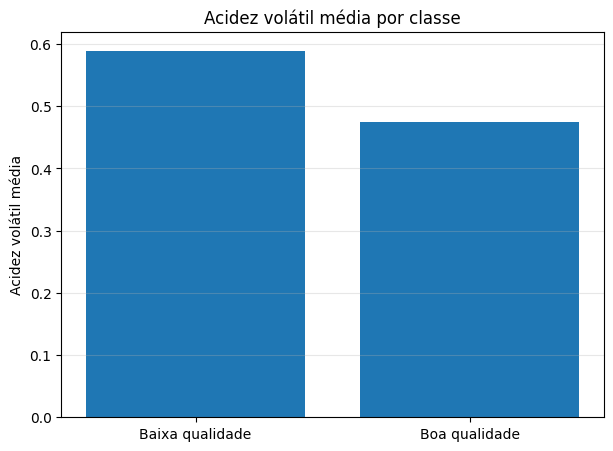

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Baixa qualidade", "Boa qualidade"],
    acidez_media.values
)

plt.title("Acidez volátil média por classe")
plt.ylabel("Acidez volátil média")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Resposta da Hipótese 2

A comparação permite verificar se os vinhos classificados como de boa qualidade possuem, em média, menor acidez volátil.

Caso isso seja observado, a variável `volatile acidity` pode ser uma característica relevante para diferenciar os grupos.

## 12. Matriz de correlação

A correlação permite identificar relações lineares entre as características físico-químicas e também verificar quais variáveis possuem maior relação com a variável `quality`.

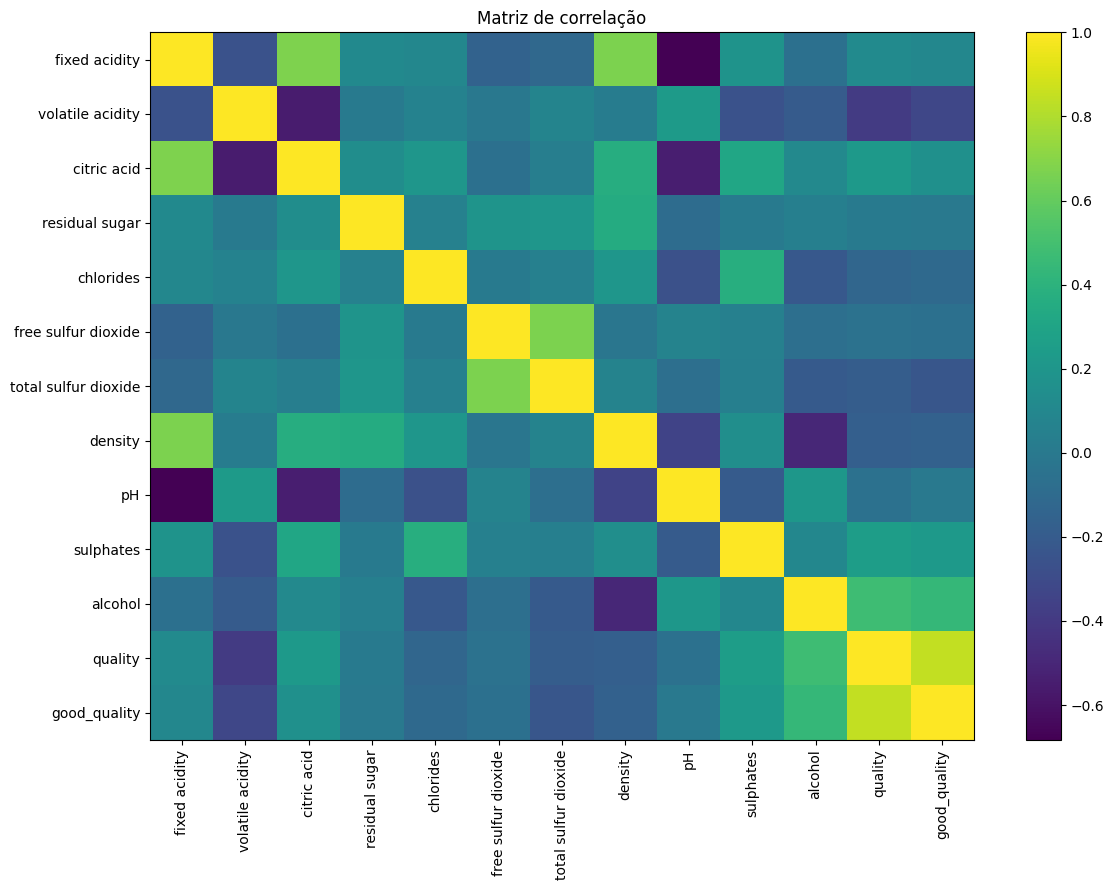

In [ ]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

plt.imshow(corr, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Matriz de correlação")

plt.tight_layout()

plt.show()

## 13. Correlação com a qualidade

Vamos ordenar as correlações com a variável `quality` para descobrir quais características apresentam maior associação linear com a nota de qualidade.

In [ ]:
correlacao_quality = (
    df.drop(columns=["good_quality"])
      .corr()["quality"]
      .sort_values(ascending=False)
)

print(correlacao_quality)

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


### Interpretação

Uma correlação positiva significa que, nos dados analisados, valores maiores de uma variável tendem a acompanhar valores maiores de `quality`.

Uma correlação negativa indica a tendência oposta.

Essa análise também ajuda a levantar hipóteses sobre quais características podem ser mais importantes para os modelos de Machine Learning.

## 14. Hipótese 3 — Quais variáveis estão mais relacionadas à qualidade?

### Pergunta

**Quais características físico-químicas apresentam maior correlação com a variável `quality`?**

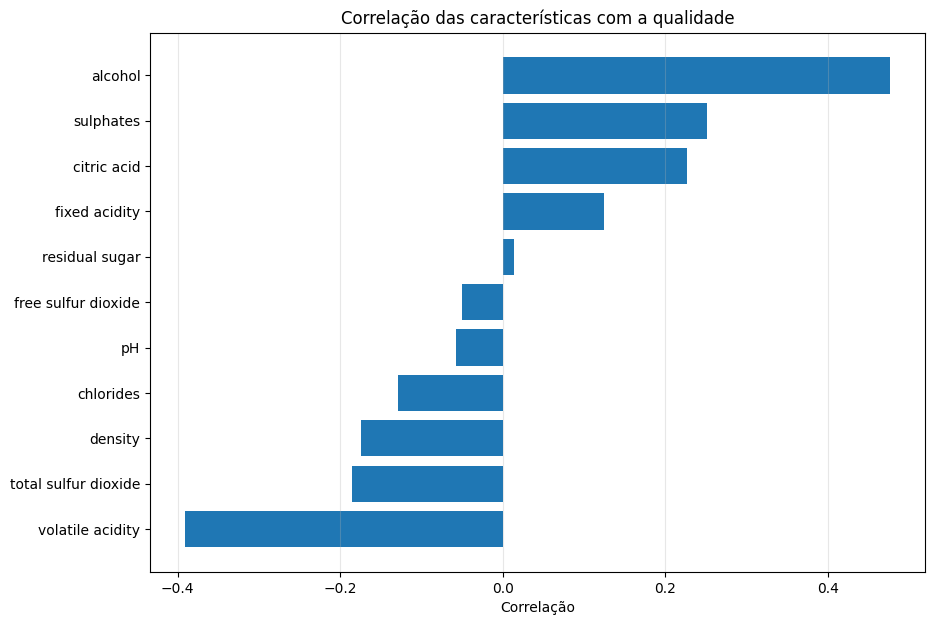

In [ ]:
correlacoes = (
    df.drop(columns=["quality", "good_quality"])
      .corrwith(df["quality"])
      .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    correlacoes.index,
    correlacoes.values
)

plt.title("Correlação das características com a qualidade")
plt.xlabel("Correlação")

plt.grid(axis="x", alpha=0.3)

plt.show()

## 15. Preparação dos dados para Machine Learning

In [ ]:
X = df.drop(columns=["quality", "good_quality"])
y = df["good_quality"]

print("Formato das variáveis de entrada:", X.shape)
print("Formato da variável alvo:", y.shape)

print("\nVariáveis utilizadas:")
print(X.columns.tolist())

Formato das variáveis de entrada: (1599, 11)
Formato da variável alvo: (1599,)

Variáveis utilizadas:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


## 16. Separação entre treino e teste

Será utilizada a proporção:

- **80% para treinamento**
- **20% para teste**

A maior parte dos dados será utilizada para que os modelos possam aprender os padrões existentes no conjunto.

Os 20% restantes serão utilizados exclusivamente para avaliar o desempenho dos modelos em dados que não foram utilizados durante o treinamento.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nDados de teste:")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

Dados de treinamento:
X_train: (1279, 11)
y_train: (1279,)

Dados de teste:
X_test: (320, 11)
y_test: (320,)


## 17. Verificação das proporções das classes

In [ ]:
print("Proporção das classes no dataset completo:")
print(y.value_counts(normalize=True))

print("\nProporção das classes no treinamento:")
print(y_train.value_counts(normalize=True))

print("\nProporção das classes no teste:")
print(y_test.value_counts(normalize=True))

Proporção das classes no dataset completo:
good_quality
1    0.534709
0    0.465291
Name: proportion, dtype: float64

Proporção das classes no treinamento:
good_quality
1    0.534793
0    0.465207
Name: proportion, dtype: float64

Proporção das classes no teste:
good_quality
1    0.534375
0    0.465625
Name: proportion, dtype: float64


# 18. Modelo 1 — K-Nearest Neighbors (KNN)

O KNN classifica um vinho observando os exemplos mais próximos no espaço das características. Como esse algoritmo utiliza distâncias, as variáveis serão padronizadas com `StandardScaler`.

A busca pelos hiperparâmetros será feita manualmente com validação cruzada. Em cada divisão, o scaler será ajustado somente nos dados de treino daquele fold e depois aplicado aos dados de validação. Assim, evitamos vazamento de informação durante a validação cruzada.


In [ ]:

parametros_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

cv_knn = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_knn_cv = []

for parametros in ParameterGrid(parametros_knn):
    acuracias_folds = []

    for indices_treino, indices_validacao in cv_knn.split(X_train, y_train):
        X_fold_treino = X_train.iloc[indices_treino]
        X_fold_validacao = X_train.iloc[indices_validacao]
        y_fold_treino = y_train.iloc[indices_treino]
        y_fold_validacao = y_train.iloc[indices_validacao]

        scaler_fold = StandardScaler()
        X_fold_treino_escalado = scaler_fold.fit_transform(X_fold_treino)
        X_fold_validacao_escalado = scaler_fold.transform(X_fold_validacao)

        modelo_fold = KNeighborsClassifier(**parametros)
        modelo_fold.fit(X_fold_treino_escalado, y_fold_treino)
        previsoes_fold = modelo_fold.predict(X_fold_validacao_escalado)
        acuracias_folds.append(accuracy_score(y_fold_validacao, previsoes_fold))

    resultados_knn_cv.append({
        "parametros": parametros,
        "acuracia_media": float(np.mean(acuracias_folds)),
        "desvio_padrao": float(np.std(acuracias_folds))
    })

melhor_resultado_knn = max(resultados_knn_cv, key=lambda resultado: resultado["acuracia_media"])
melhores_parametros_knn = melhor_resultado_knn["parametros"]
melhor_score_knn = melhor_resultado_knn["acuracia_media"]

# Ajuste final do scaler e do KNN usando todo o conjunto de treinamento.
knn_scaler = StandardScaler()
X_train_knn_escalado = knn_scaler.fit_transform(X_train)
knn_model = KNeighborsClassifier(**melhores_parametros_knn)
knn_model.fit(X_train_knn_escalado, y_train)

print("Melhores parâmetros encontrados:")
print(melhores_parametros_knn)
print("\nMelhor acurácia média na validação cruzada:")
print(f"{melhor_score_knn:.4f}")

Melhores parâmetros encontrados:
{'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}

Melhor acurácia média na validação cruzada:
0.7928


## 19. Avaliação do KNN

Agora o melhor KNN encontrado pela validação cruzada será utilizado para fazer previsões no conjunto de teste.

Serão analisadas:

- Acurácia
- Precisão
- Recall
- F1-score
- Matriz de confusão

In [ ]:
# O scaler ajustado no treino também transforma os dados de teste.
X_test_knn_escalado = knn_scaler.transform(X_test)
y_pred_knn = knn_model.predict(X_test_knn_escalado)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)

print("RESULTADOS DO KNN")
print("=" * 40)

print(f"Acurácia : {accuracy_knn:.4f}")
print(f"Precisão : {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_knn, zero_division=0))


RESULTADOS DO KNN
Acurácia : 0.8000
Precisão : 0.8057
Recall   : 0.8246
F1-score : 0.8150

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.79      0.77      0.78       149
           1       0.81      0.82      0.82       171

    accuracy                           0.80       320
   macro avg       0.80      0.80      0.80       320
weighted avg       0.80      0.80      0.80       320



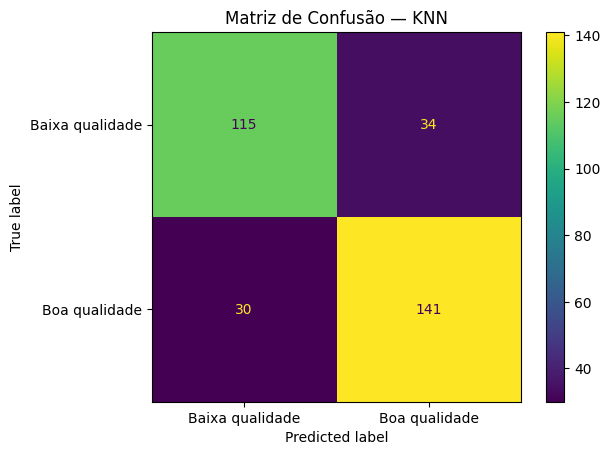

In [ ]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Baixa qualidade", "Boa qualidade"]
)

disp.plot()

plt.title("Matriz de Confusão — KNN")
plt.show()

# 20. Modelo 2 — Random Forest

O Random Forest é um método baseado em várias árvores de decisão.

Cada árvore aprende diferentes padrões dos dados e, no final, as previsões são combinadas.

Uma vantagem do Random Forest é sua capacidade de lidar com relações não lineares entre as características.

Também será utilizado `GridSearchCV` para buscar uma configuração adequada do modelo.

In [ ]:
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

parametros_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_rf = GridSearchCV(
    rf,
    parametros_rf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Melhores parâmetros encontrados:")
print(grid_rf.best_params_)

print("\nMelhor acurácia média na validação cruzada:")
print(f"{grid_rf.best_score_:.4f}")

Melhores parâmetros encontrados:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

Melhor acurácia média na validação cruzada:
0.8139


## 21. Avaliação do Random Forest

O melhor Random Forest encontrado na validação cruzada será avaliado utilizando o conjunto de teste.

In [ ]:
rf_model = grid_rf.best_estimator_

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("RESULTADOS DO RANDOM FOREST")
print("=" * 40)

print(f"Acurácia : {accuracy_rf:.4f}")
print(f"Precisão : {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RESULTADOS DO RANDOM FOREST
Acurácia : 0.8094
Precisão : 0.8313
Recall   : 0.8070
F1-score : 0.8190

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       149
           1       0.83      0.81      0.82       171

    accuracy                           0.81       320
   macro avg       0.81      0.81      0.81       320
weighted avg       0.81      0.81      0.81       320



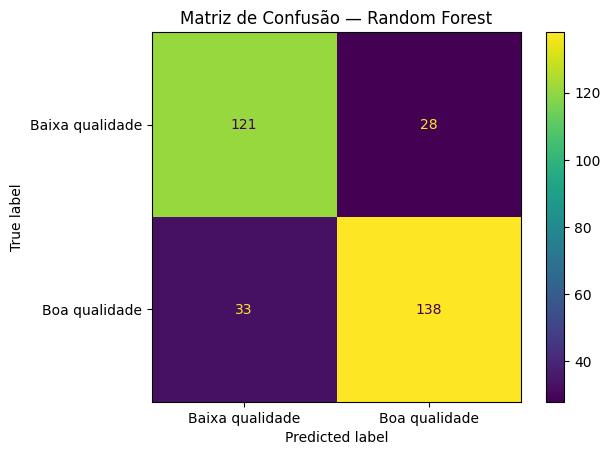

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Baixa qualidade", "Boa qualidade"]
)

disp.plot()

plt.title("Matriz de Confusão — Random Forest")
plt.show()

# 22. Comparação dos modelos

Agora vamos comparar os resultados dos dois algoritmos.

As principais métricas utilizadas serão:

- **Acurácia:** proporção de previsões corretas.
- **Precisão:** entre os exemplos classificados como boa qualidade, quantos realmente eram de boa qualidade.
- **Recall:** entre os vinhos realmente classificados como boa qualidade, quantos foram identificados corretamente.
- **F1-score:** média harmônica entre precisão e recall.

A comparação permitirá determinar qual modelo apresentou o melhor desempenho no conjunto de teste.

In [ ]:
resultados = pd.DataFrame({
    "Modelo": ["KNN", "Random Forest"],
    "Acurácia": [accuracy_knn, accuracy_rf],
    "Precisão": [precision_knn, precision_rf],
    "Recall": [recall_knn, recall_rf],
    "F1-score": [f1_knn, f1_rf]
})

resultados

,Modelo,Acurácia,Precisão,Recall,F1-score
0,KNN,0.800000,0.805714,0.824561,0.815029
1,Random Forest,0.809375,0.831325,0.807018,0.818991


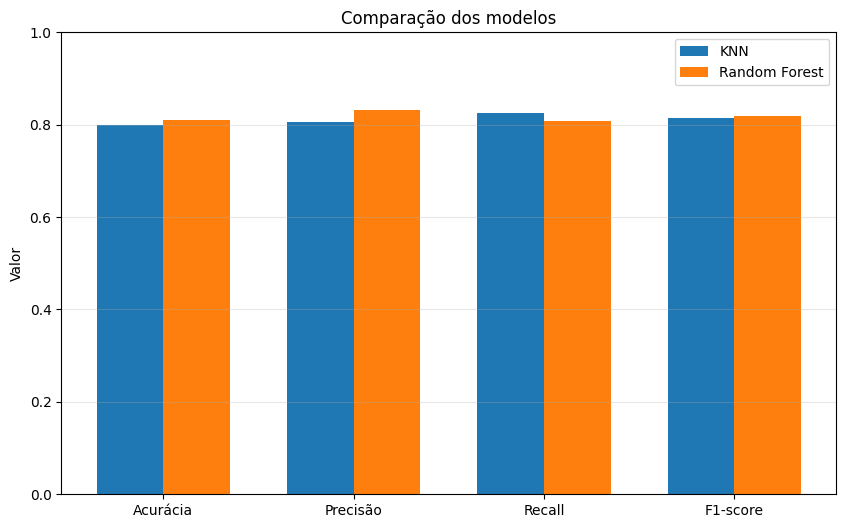

In [ ]:
metricas = ["Acurácia", "Precisão", "Recall", "F1-score"]

x = np.arange(len(metricas))
largura = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - largura/2,
    resultados.loc[0, metricas].values,
    largura,
    label="KNN"
)

plt.bar(
    x + largura/2,
    resultados.loc[1, metricas].values,
    largura,
    label="Random Forest"
)

plt.xticks(x, metricas)
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.title("Comparação dos modelos")
plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.show()

# 23. Discussão dos resultados

Os dois modelos foram treinados utilizando exatamente o mesmo conjunto de treinamento e avaliados no mesmo conjunto de teste.

O KNN utiliza a proximidade entre os exemplos para realizar a classificação. Por isso, a padronização das variáveis é importante, já que características com escalas maiores poderiam influenciar excessivamente o cálculo das distâncias.

O Random Forest, por outro lado, utiliza um conjunto de árvores de decisão e consegue representar relações não lineares entre as características.

A partir das métricas obtidas, podemos comparar os dois métodos e verificar qual apresentou maior capacidade de generalização.

Além da acurácia, o F1-score, precisão e recall também são importantes para verificar se o modelo não está apenas acertando a classe majoritária.

O modelo escolhido como melhor será aquele que apresentar o maior desempenho geral, considerando principalmente a acurácia e o equilíbrio entre precisão e recall.

## 24. Verificação do requisito de acurácia

In [ ]:
print(f"Acurácia KNN: {accuracy_knn:.2%}")
print(f"Acurácia Random Forest: {accuracy_rf:.2%}")

Acurácia KNN: 80.00%
Acurácia Random Forest: 80.94%


# 25. Importância das características — Random Forest

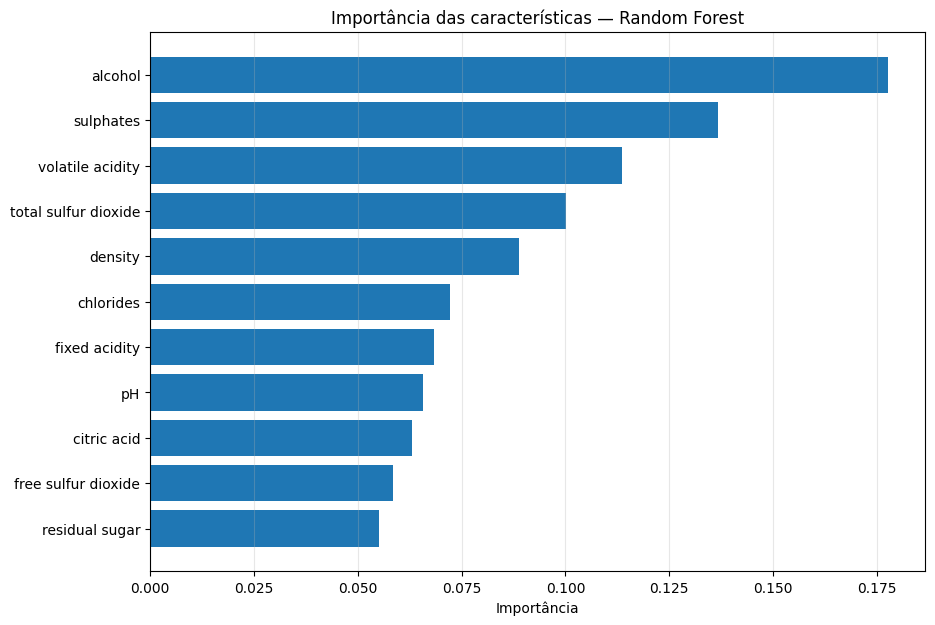

In [ ]:
importancias = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(
    importancias.index,
    importancias.values
)

plt.title("Importância das características — Random Forest")
plt.xlabel("Importância")

plt.grid(axis="x", alpha=0.3)

plt.show()

## 26. Resposta à pergunta sobre as características mais importantes

O gráfico anterior apresenta quais variáveis tiveram maior importância para o Random Forest.

Essa análise complementa a matriz de correlação.

É importante destacar que **correlação e importância no modelo são conceitos diferentes**. Uma variável pode apresentar uma correlação linear relativamente baixa com a qualidade e ainda assim ser útil para o modelo devido a relações não lineares ou interações com outras variáveis.

# 27. Escolha do melhor modelo

In [ ]:
if accuracy_rf >= accuracy_knn:
    melhor_modelo = rf_model
    melhor_scaler = None
    nome_modelo = "Random Forest"
    melhor_acuracia = accuracy_rf
else:
    melhor_modelo = knn_model
    melhor_scaler = knn_scaler
    nome_modelo = "KNN"
    melhor_acuracia = accuracy_knn

print(f"Melhor modelo: {nome_modelo}")
print(f"Acurácia: {melhor_acuracia:.4f}")


Melhor modelo: Random Forest
Acurácia: 0.8094


In [ ]:
arquivo_modelo = "melhor_modelo_wine_quality.joblib"

pacote_inicial = {
    "modelo": melhor_modelo,
    "scaler": melhor_scaler,
    "nome_modelo": nome_modelo
}
joblib.dump(pacote_inicial, arquivo_modelo)

print(f"Modelo salvo com sucesso em: {arquivo_modelo}")


Modelo salvo com sucesso em: melhor_modelo_wine_quality.joblib


# 28. Testando o modelo salvo

In [ ]:
pacote_carregado = joblib.load("melhor_modelo_wine_quality.joblib")
modelo_carregado = pacote_carregado["modelo"]
scaler_carregado = pacote_carregado["scaler"]

if scaler_carregado is not None:
    X_test_salvo = scaler_carregado.transform(X_test)
else:
    X_test_salvo = X_test

y_pred_salvo = modelo_carregado.predict(X_test_salvo)
acuracia_modelo_salvo = accuracy_score(y_test, y_pred_salvo)

print("Modelo carregado com sucesso!")
print(f"Acurácia do modelo salvo: {acuracia_modelo_salvo:.4f}")


Modelo carregado com sucesso!
Acurácia do modelo salvo: 0.8094


## 29.salvamento

In [ ]:
# Baixar o pacote com modelo, limiar e nomes das características
from google.colab import files
files.download("melhor_modelo_wine_quality.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>